# A second data set: the Larsch lab screen

The models on a second, much larger data set (unpublished; `data/README.md`): one fish per 70 mm dish and a single
dot always on screen, in alternating bout-like and continuous episodes. F zero-shot (trained on our 15 fish), and
D4 trained from scratch on 100 screen fish, with and without the dot's direction of motion as an input. Every
result is cached in `output/screen/`; the commands that make them:

    uv run python -m twin.twin_test extract-meta        # the screen's metadata
    uv run python -m twin.twin_test real                # real screen fish, per-fish sums -> real.pkl
    uv run python -m twin.screen_eval real              # real screen fish -> screen_raw_real.pkl
    uv run python -m twin.screen_eval sim               # F zero-shot (and blind) on the screen
    uv run python -m twin.screen_eval analyse           # -> screen_eval.json
    uv run python -m twin.screen_train build            # the screen bout table
    uv run python -m twin.screen_train run              # D4 (+ direction) trained on the screen, both seeds
    uv run python -m twin.screen_train sim              # their simulations
    uv run python -m twin.screen_train analyse          # -> screen_trained_eval.json
    uv run python -m twin.screen_matched                # matched window classifier -> screen_matched.json
    uv run python -m twin.screen_report_extras importances
    uv run python -m twin.screen_report_extras closerange
    uv run python -m twin.grouprep_fit fit 14f          # the group repulsion term (also for 32b): calibration
    uv run python -m twin.grouprep_fit test 14f         #   and the held-out screen test

In [1]:
import json
import numpy as np
import pandas as pd
from twin import paths
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
TW = paths.SCREEN_OUT

## The fish
The reference siblings (sighted, in the screen's contrasts, no exclusion) and their clutches, split once at random
into a calibration half (the group repulsion term is fitted on it) and a test half.

In [2]:
import pickle
meta = pickle.load(open(TW / "real.pkl", "rb"))["meta"]
split = json.load(open(TW / "clutch_split.json"))
ref = [c for g, c in zip(meta["group"], meta["clutch"]) if g == "ref"]
print(f"{len(ref):,} reference fish in {len(set(ref))} clutches; blind mutants: {sum(g == 'blind' for g in meta['group'])}")
for half in ("fit", "test"):
    s = set(split[half])
    print(f"  {'calibration' if half == 'fit' else 'test'} half: {len(s)} clutches, {sum(c in s for c in ref):,} fish")

2,819 reference fish in 198 clutches; blind mutants: 26
  calibration half: 99 clutches, 1,352 fish
  test half: 99 clutches, 1,467 fish


## Matched window classifier (Table tab:screen-auc)
AUC of real screen fish (the 98 clutches not used to train D4) against each sample, mean over 8 replicates;
seed 0 | seed 101.

In [3]:
MA = json.load(open(TW / "screen_matched.json"))
READINGS = {"all": "all", "15": "all, 15 fish", "no radial": "no radial", "dot only": "fish-to-dot",
            "30 features": "turn, step, interval"}


def auc(reading, unit):
    for B in (MA["pool"], MA["screen-trained"]):
        d = B["auc15"] if reading == "15" else B["auc"][reading]
        if unit in d:
            return np.mean(d[unit])


def pair(reading, unit):
    return f"{auc(reading, unit.format(s=0)):.3f} | {auc(reading, unit.format(s=101)):.3f}"


rows = {"real": {lab: f"{auc(r, 'real vs real'):.3f}" for r, lab in READINGS.items()}}
rows["15 fish of the main data set"] = {"turn, step, interval": f"{np.mean(MA['pool']['our15_30features']):.3f}"}
for name, unit in (("F", "F zero-shot s{s} sighted"), ("F, blind", "F zero-shot s{s} blind"),
                   ("D4", "D4 screen s{s} sighted"), ("D4, decoupled", "D4 screen s{s} decoupled"),
                   ("D4 + direction", "D4dm screen s{s} sighted"),
                   ("D4 + direction, decoupled", "D4dm screen s{s} decoupled")):
    rows[name] = {lab: pair(r, unit) for r, lab in READINGS.items()}
pd.DataFrame(rows).T.fillna("--")

,all,"all, 15 fish",no radial,fish-to-dot,"turn, step, interval"
real,0.513,0.550,0.505,0.498,0.506
15 fish of the main data set,--,--,--,--,0.873
F,0.953 | 0.956,0.885 | 0.896,0.941 | 0.946,0.734 | 0.766,0.931 | 0.938
"F, blind",0.966 | 0.963,0.914 | 0.922,0.953 | 0.951,0.825 | 0.841,0.921 | 0.920
D4,0.873 | 0.844,0.766 | 0.751,0.848 | 0.815,0.704 | 0.667,0.820 | 0.773
"D4, decoupled",0.924 | 0.917,0.866 | 0.871,0.908 | 0.897,0.835 | 0.827,0.819 | 0.773
D4 + direction,0.826 | 0.842,0.703 | 0.745,0.794 | 0.809,0.631 | 0.639,0.771 | 0.783
"D4 + direction, decoupled",0.922 | 0.919,0.875 | 0.874,0.904 | 0.899,0.841 | 0.832,0.771 | 0.782


## Response to the dot (Figures fig:screen-response and fig:screen-switch)

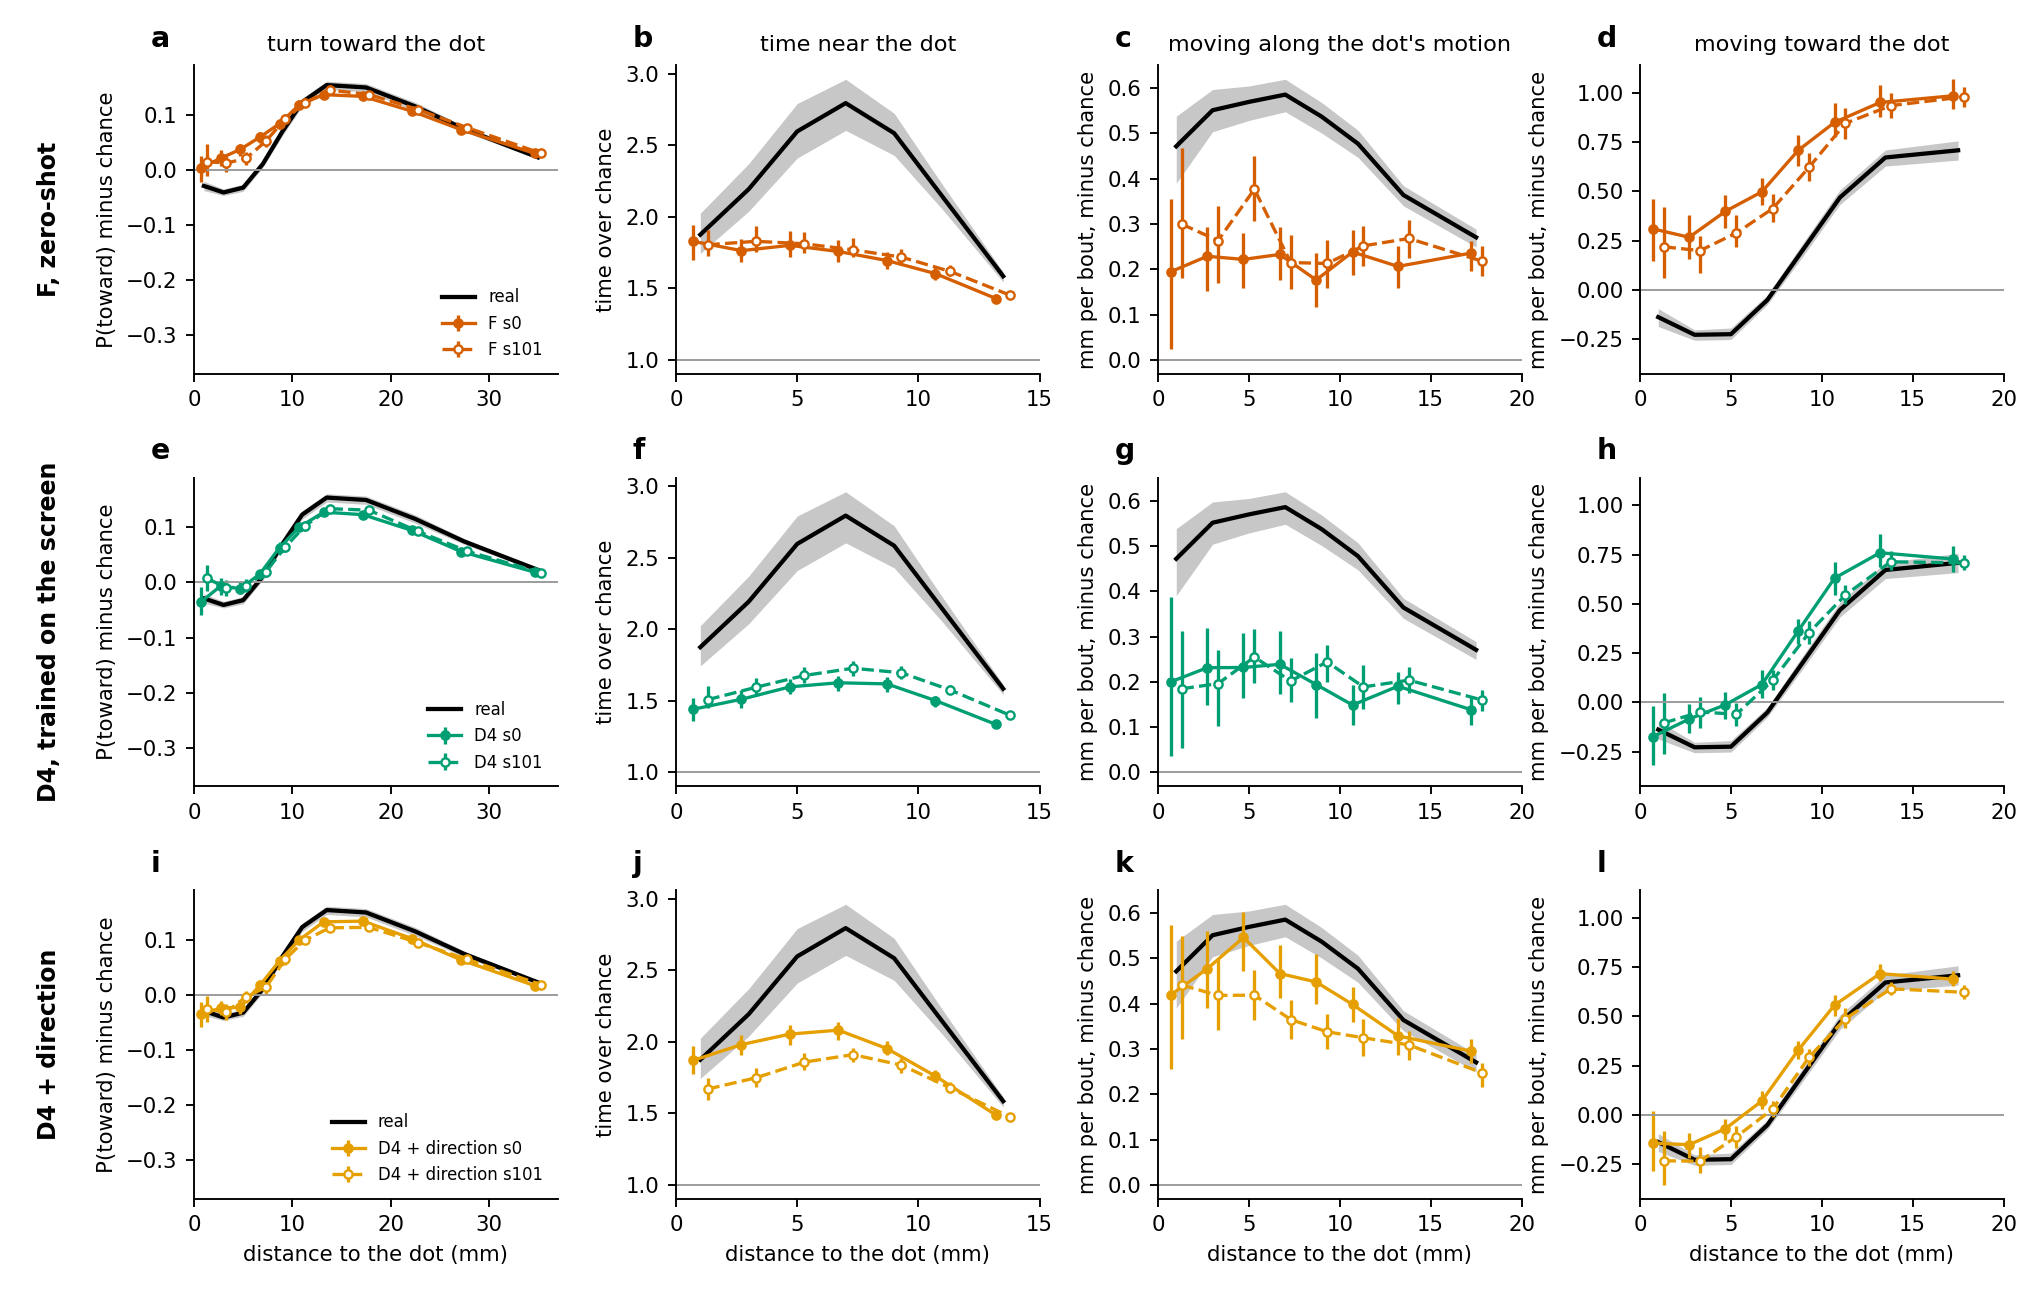

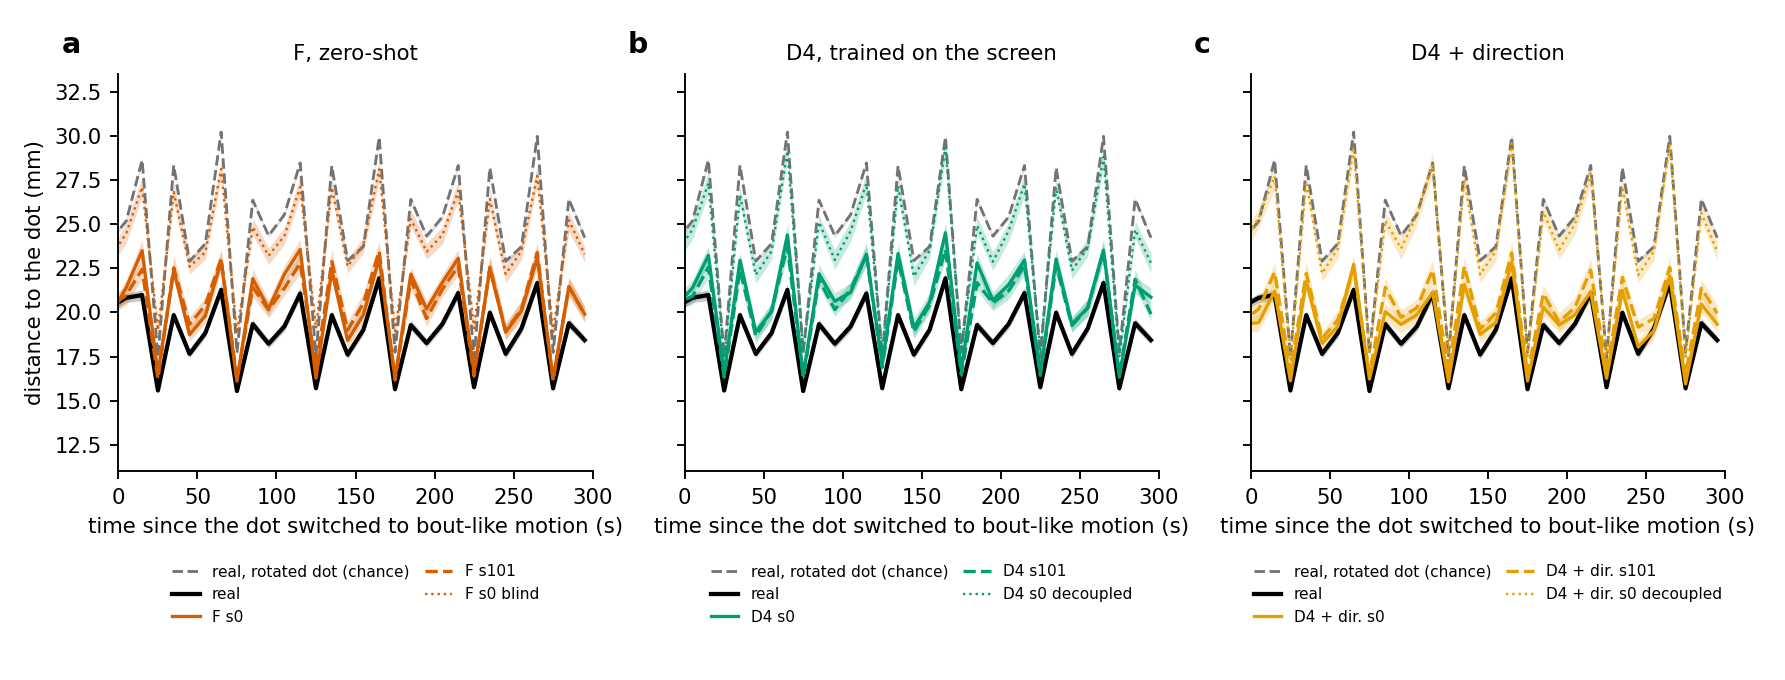

In [4]:
from figures import fig_screen
fig_screen.fig_screen_merged()
fig_screen.fig_switch_noM6()

## Kinematics and individuality on the screen (Table tab:app-screen-kin)
Top: per-fish mean over 60-bout windows, median over fish (|turn| deg, displacement mm, interval s, the interval's
SD within a window, radial position r/R). Bottom: between- and within-fish spread, simulated over real.

In [5]:
K = json.load(open(TW / "screen_kin_table.json"))
cols = ["|turn| (deg)", "displacement (mm)", "interval (s)", "interval SD (s)", "r/R"]
show = ["real screen (all)", "real screen (held-out clutches)", "our 15 fish", "F zero-shot s0", "F zero-shot s101",
        "D4 screen s0", "D4 screen s101"]
display(pd.DataFrame({k: dict(zip(cols, np.round(K[k]["kin"], 2)), n=K[k]["n"]) for k in show}).T)
ch = ["turn", "displacement", "interval", "radial"]
pd.DataFrame({k: {**{f"between {c}": round(v, 2) for c, v in zip(ch, K[k]["between"])},
                  **{f"within {c}": round(v, 2) for c, v in zip(ch, K[k]["within"])}} for k in show[3:]}).T

,|turn| (deg),displacement (mm),interval (s),interval SD (s),r/R,n
real screen (all),37.66,4.22,1.17,0.57,0.47,2809.0
real screen (held-out clutches),38.08,4.25,1.17,0.57,0.47,1453.0
our 15 fish,41.61,4.54,1.39,0.75,NaN,15.0
F zero-shot s0,44.60,4.65,1.35,0.81,0.46,200.0
F zero-shot s101,44.43,4.74,1.44,0.91,0.46,200.0
D4 screen s0,37.44,4.31,1.26,0.70,0.47,200.0
D4 screen s101,38.60,4.17,1.21,0.67,0.47,200.0


,between turn,between displacement,between interval,between radial,within turn,within displacement,within interval,within radial
F zero-shot s0,1.25,1.44,2.30,0.66,1.36,1.65,1.23,0.76
F zero-shot s101,1.06,0.97,1.86,0.43,1.32,1.95,1.45,0.79
D4 screen s0,1.81,1.77,1.81,0.73,1.66,1.44,1.70,0.87
D4 screen s101,0.78,1.27,0.69,0.55,1.46,1.49,1.57,0.88


## What tells the models from the screen fish (Table tab:app-screen-importances)
Permutation importance of every window feature on the matched classifier (x 1000).

In [6]:
I = json.load(open(TW / "screen_importances.json"))
units = [k for k in I if k.startswith(("F zero-shot", "D4 screen"))]
display(pd.DataFrame({k: pd.Series(I[k]["imp"], index=I[k]["names"]) for k in units}).mul(1000).round(1))
pd.DataFrame({k: {**I[k]["share"], "AUC (this replicate)": I[k]["auc"]} for k in units}).round(3)

,F zero-shot s0,F zero-shot s101,D4 screen s0,D4 screen s101
uni_F,1.1,1.3,0.6,0.6
uni_L,0.2,0.2,-0.2,-0.5
uni_R,0.1,-0.1,-0.2,-0.1
T_FF,0.2,0.4,0.7,0.3
T_FL,0.1,0.2,0.0,0.1
T_FR,0.0,0.1,-0.2,0.3
T_LF,0.0,0.3,-0.3,0.6
T_LL,1.4,1.7,0.1,0.1
T_LR,1.3,0.6,2.0,1.6
T_RF,0.1,0.1,0.7,0.7


,F zero-shot s0,F zero-shot s101,D4 screen s0,D4 screen s101
turn,0.162,0.132,0.104,0.138
distance,0.230,0.326,0.116,0.141
dt,0.362,0.360,0.441,0.250
dot-dist,0.063,0.043,0.184,0.247
radial,0.183,0.139,0.155,0.225
AUC (this replicate),0.950,0.949,0.865,0.832


## The group repulsion term (Figure fig:app-grouprep, Table tab:app-grouprep)
Calibrated on the screen: F without the term and with it at 1, 2, 4 and 8 times the calibrated strength, on the
test half of the clutches. Turn away: the turn toward the dot at 0-4 mm as a share of the real effect (real fish turn
away); attraction: distance gained per bout at 6-20 mm as a share of the real effect; bouts starting 4-8 mm from the
dot, over chance (real 2.61).

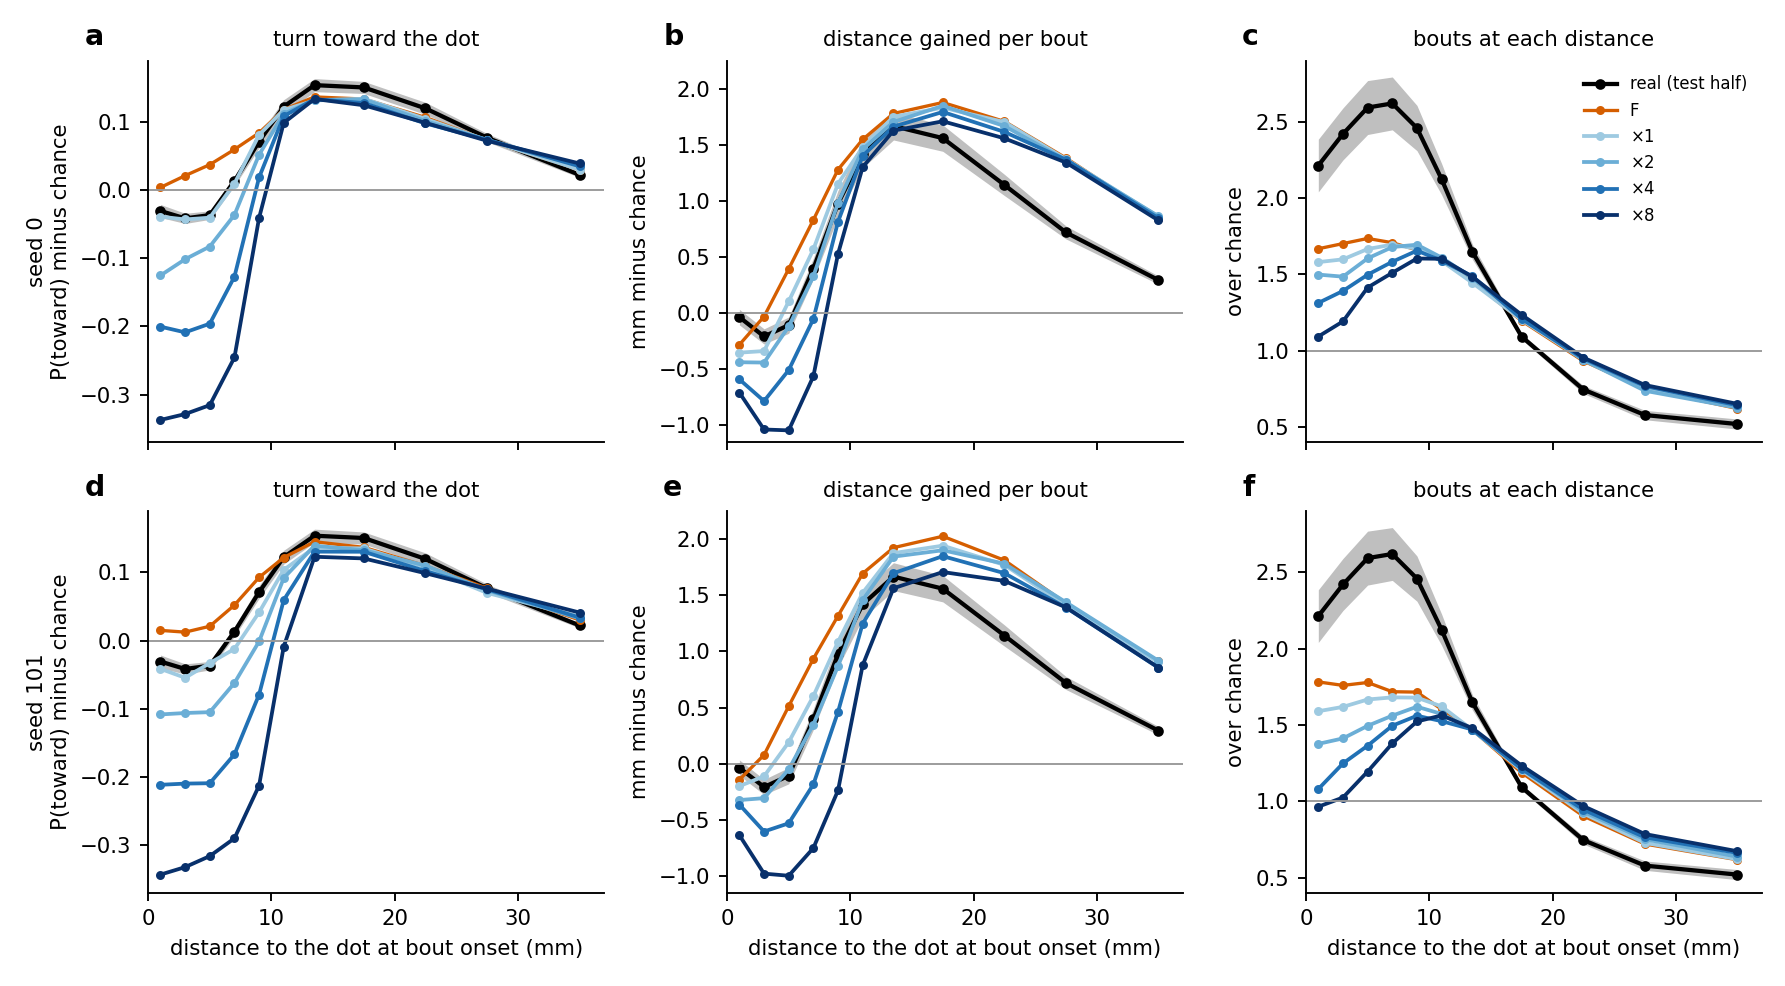

In [7]:
from figures import fig_app_grouprep
fig_app_grouprep.main()

In [8]:
G = {s: json.load(open(TW / f"grtest_{k}.json")) for s, k in ((0, "14f"), (101, "32b"))}
V = {"F": "F", "grT": "x1", "grT2": "x2", "grT4": "x4", "grT8": "x8"}
pd.DataFrame({lab: {r: " | ".join(f"{G[s]['variants'][v]['shares'][q]:.2f}" for s in (0, 101))
                    for r, q in (("turn away, share", "turn_away_0_4"), ("attraction, share", "attraction_6_20"),
                                 ("bouts at 4-8 mm", "occ_4_8"))} for v, lab in V.items()})

,F,x1,x2,x4,x8
"turn away, share",-0.35 | -0.38,1.14 | 1.33,3.14 | 2.97,5.66 | 5.83,9.22 | 9.35
"attraction, share",1.21 | 1.31,1.13 | 1.17,1.05 | 1.07,0.93 | 0.84,0.76 | 0.52
bouts at 4-8 mm,1.72 | 1.75,1.68 | 1.67,1.64 | 1.53,1.54 | 1.43,1.46 | 1.29
